# Portafolio 1/3 · Regresión: predecir ventas de helados

Primer modelo del mini portafolio del Curso 06. El ejercicio del curso entrena **un** modelo de regresión con la app ML Lite; aquí la pregunta es otra: **¿qué algoritmo conviene para este problema, y cómo lo demuestro?**

Plan:

1. Preparar los datos (igual que la app: sin `Date`, el resto como features).
2. Definir una **línea base** (`DummyRegressor`, predice siempre la media). Cualquier modelo que no la supere no sirve.
3. Comparar 4 algoritmos con **validación cruzada** sobre el conjunto de entrenamiento.
4. Confirmar con el conjunto de prueba, que ningún modelo ha visto.
5. Predecir los dos casos de prueba del ejercicio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
helados = pd.read_csv('../datasets/ice-cream.csv')
print(f'{len(helados)} días registrados')
helados.head()

200 días registrados


,Date,DayOfWeek,Month,Temperature,Rainfall,IceCreamsSold
0,2025-04-01,Tuesday,April,59.4,0.74,61
1,2025-04-03,Thursday,April,53.6,0.28,33
2,2025-04-06,Sunday,April,51.4,0.14,21
3,2025-04-07,Monday,April,50.8,0.06,23
4,2025-04-08,Tuesday,April,57.4,0.79,51


## Preparación

- `Date` se descarta: es distinta cada día, así que no puede generalizar.
- `DayOfWeek` y `Month` son texto → **one-hot**.
- `Temperature` y `Rainfall` pasan tal cual. Ninguno de los algoritmos comparados aquí depende de distancias, así que no hace falta escalar.

Todo va dentro de un `Pipeline`: así la transformación se aprende **solo** con los datos de entrenamiento de cada pliegue y se aplica igual al predecir.

In [2]:
categoricas = ['DayOfWeek', 'Month']
numericas = ['Temperature', 'Rainfall']
X = helados[categoricas + numericas]
y = helados['IceCreamsSold']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEMILLA)
print(f'Entrenamiento: {len(X_train)} · Prueba: {len(X_test)}')

preparacion = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas),
    ('num', 'passthrough', numericas),
])

Entrenamiento: 140 · Prueba: 60


## Candidatos

| Algoritmo | Por qué está en la comparación |
|---|---|
| Media (`DummyRegressor`) | Línea base: el mínimo que hay que superar |
| Regresión lineal | El más simple e interpretable |
| Árbol de decisión | Capta relaciones no lineales, pero tiende a sobreajustar |
| Bosque aleatorio | Conjunto de árboles: reduce el sobreajuste de un árbol solo |
| Gradient boosting | Conjunto secuencial: cada árbol corrige los errores del anterior |

In [3]:
candidatos = {
    'Media (línea base)': DummyRegressor(strategy='mean'),
    'Regresión lineal': LinearRegression(),
    'Árbol de decisión': DecisionTreeRegressor(random_state=SEMILLA),
    'Bosque aleatorio': RandomForestRegressor(n_estimators=200, random_state=SEMILLA),
    'Gradient boosting': GradientBoostingRegressor(random_state=SEMILLA),
}

def pipeline(modelo):
    return Pipeline([('prep', preparacion), ('modelo', modelo)])

## Validación cruzada (5 pliegues, solo con entrenamiento)

Un único reparto entrenamiento/prueba puede salir favorable o desfavorable por azar. La validación cruzada entrena y evalúa 5 veces con repartos distintos y da la **media** y la **desviación**: si la desviación es grande, el resultado no es fiable.

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(pipeline(modelo), X_train, y_train, cv=cv, scoring=metricas)
    filas.append({'Modelo': nombre,
                  'MAE (CV)': -r['test_MAE'].mean(),
                  'RMSE (CV)': -r['test_RMSE'].mean(),
                  'R² (CV)': r['test_R2'].mean(),
                  'R² desv.': r['test_R2'].std()})

tabla_cv = pd.DataFrame(filas).set_index('Modelo').sort_values('RMSE (CV)')
tabla_cv.round(3)

,MAE (CV),RMSE (CV),R² (CV),R² desv.
Modelo,,,,
Regresión lineal,3.996,5.024,0.992,0.002
Gradient boosting,5.252,6.521,0.987,0.003
Bosque aleatorio,5.690,6.806,0.986,0.003
Árbol de decisión,7.414,9.081,0.975,0.008
Media (línea base),50.553,59.835,-0.039,0.045


## Confirmación con el conjunto de prueba

Cada modelo se entrena con **todo** el conjunto de entrenamiento y se evalúa una sola vez sobre la prueba. Se reportan las cuatro métricas del módulo 4.

In [5]:
entrenados, filas = {}, []
for nombre, modelo in candidatos.items():
    p = pipeline(modelo).fit(X_train, y_train)
    entrenados[nombre] = p
    pred = p.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    filas.append({'Modelo': nombre, 'MAE': mean_absolute_error(y_test, pred), 'MSE': mse,
                  'RMSE': np.sqrt(mse), 'R²': r2_score(y_test, pred)})

tabla_test = pd.DataFrame(filas).set_index('Modelo').sort_values('RMSE')
tabla_test.round(3)

,MAE,MSE,RMSE,R²
Modelo,,,,
Regresión lineal,4.590,31.923,5.650,0.989
Bosque aleatorio,4.939,45.408,6.739,0.984
Gradient boosting,5.235,47.340,6.880,0.983
Árbol de decisión,5.800,64.433,8.027,0.977
Media (línea base),43.540,2903.870,53.888,-0.026


Mejor modelo en prueba: Regresión lineal


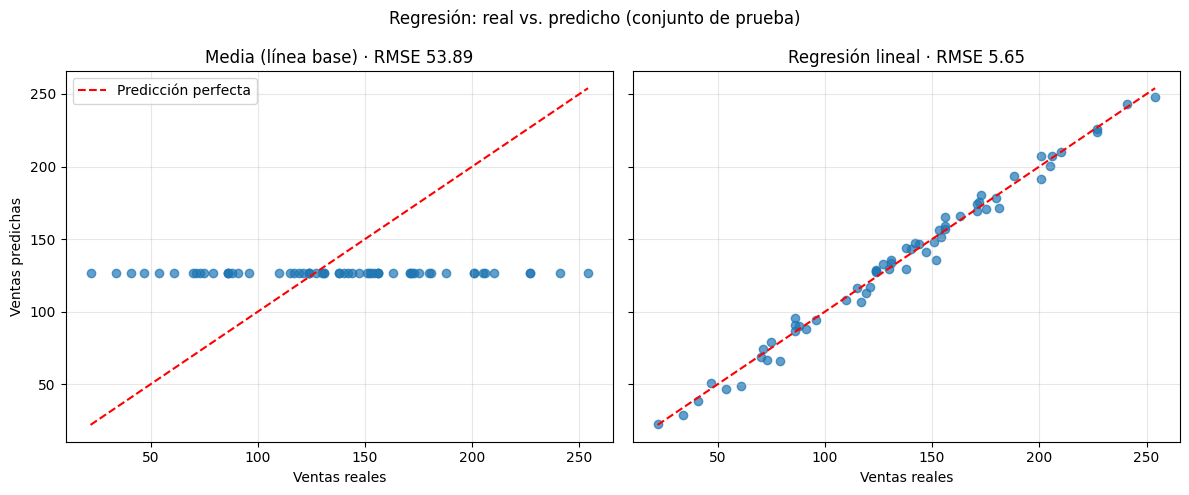

In [6]:
mejor = tabla_test.index[0]
print(f'Mejor modelo en prueba: {mejor}')

fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for eje, nombre in zip(ejes, ['Media (línea base)', mejor]):
    pred = entrenados[nombre].predict(X_test)
    eje.scatter(y_test, pred, alpha=0.7)
    lim = [y_test.min(), y_test.max()]
    eje.plot(lim, lim, 'r--', label='Predicción perfecta')
    eje.set_title(f'{nombre} · RMSE {tabla_test.loc[nombre, "RMSE"]:.2f}')
    eje.set_xlabel('Ventas reales')
    eje.grid(alpha=0.3)
ejes[0].set_ylabel('Ventas predichas')
ejes[0].legend()
plt.suptitle('Regresión: real vs. predicho (conjunto de prueba)')
plt.tight_layout()
plt.savefig('../imagenes/regresion-real-vs-prediccion.png', dpi=110, bbox_inches='tight')
plt.show()

## ¿Por qué gana la regresión lineal? Mirando el modelo por dentro

Una ventaja de la regresión lineal es que se puede leer: cada coeficiente dice cuántos helados suma o resta esa feature.

In [7]:
lineal = entrenados['Regresión lineal']
nombres = lineal.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lineal.named_steps['modelo'].coef_, index=[n.split('__')[1] for n in nombres])
coef[['Temperature', 'Rainfall']].round(2)

Temperature    5.10
Rainfall      -8.37
dtype: float64

## Casos de prueba del ejercicio

Los mismos dos días que propone el ejercicio de ML Lite, predichos con el mejor modelo.

In [8]:
casos = pd.DataFrame({'DayOfWeek': ['Friday', 'Monday'], 'Month': ['May', 'November'],
                      'Temperature': [72.3, 55.8], 'Rainfall': [0.01, 0.56]}, index=['Caso 1', 'Caso 2'])
casos['Predicción'] = entrenados[mejor].predict(casos).round(0).astype(int)
casos

,DayOfWeek,Month,Temperature,Rainfall,Predicción
Caso 1,Friday,May,72.3,0.01,130
Caso 2,Monday,November,55.8,0.56,41


## Conclusiones

- **Gana el modelo más simple.** La regresión lineal es la mejor en validación cruzada (RMSE 5.02, R² 0.992) y en prueba (RMSE 5.65, R² 0.989). Los modelos basados en árboles, más complejos, quedan por detrás. Señal de que la relación entre clima y ventas es esencialmente lineal: más complejidad no aporta nada que capturar.
- **La línea base confirma que el modelo aprende algo.** Predecir siempre la media da un R² cercano a 0 (negativo incluso) y un error de ~54 helados. El modelo lineal lo reduce a ~5.7.
- **El modelo se puede leer.** Cada grado de temperatura suma unos 5 helados; cada pulgada de lluvia resta unos 8.
- **Un solo reparto no basta para ordenar los modelos.** El bosque aleatorio y el gradient boosting intercambian posiciones entre la validación cruzada y la prueba; sus diferencias son pequeñas. La validación cruzada (con su desviación) es la que permite afirmar algo con confianza.
- **Las métricas de prueba son algo peores que las de CV.** Es normal: son 60 días concretos, y la CV promedia 5 repartos distintos.

**Modelo elegido:** regresión lineal.